# 02 — Modelo de cadenas de Markov: matriz de transición, clasificación de estados y tiempo hasta cancelación


## 1. Carga de datos

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:.4f}".format

RUTA_LOCAL = "../data/processed/telco_estados.csv"
URL_REPO = "https://raw.githubusercontent.com/moonleaal/churn-markov-expoing/main/data/processed/telco_estados.csv"

print("Clientes:", len(df))
df.head()

Clientes: 7032


,customerID,contrato,tenure,etapa,estado_actual,churn,MonthlyCharges,TotalCharges
0,7590-VHVEG,Mensual,1,E1: 1-12,E1: 1-12,0,29.8500,29.8500
1,5575-GNVDE,1 año,34,E3: 25-48,E3: 25-48,0,56.9500,1889.5000
2,3668-QPYBK,Mensual,2,E1: 1-12,E5: Cancelado,1,53.8500,108.1500
3,7795-CFOCW,1 año,45,E3: 25-48,E3: 25-48,0,42.3000,1840.7500
4,9237-HQITU,Mensual,2,E1: 1-12,E5: Cancelado,1,70.7000,151.6500


## 2. Parámetros: etapas y contratos
Las etapas son las que definimos en el notebook 01. `LONG` es la duración (en meses) de cada etapa; E4 es la última (clientes de 49 a 72 meses) y no tiene etapa siguiente.

In [3]:
ETAPAS = ["E1", "E2", "E3", "E4"]
LIMITES = [(1, 12), (13, 24), (25, 48), (49, 72)]   # (mes inicial, mes final) de cada etapa
LONG = [12, 12, 24, 24]                             # duración de cada etapa en meses
CONTRATOS = ["Mensual", "1 año", "2 años"]
ESTADOS = ["E1", "E2", "E3", "E4", "E5 (cancelado)"]

## 3. Estimación de la probabilidad mensual de cancelación (meses en riesgo)


El dataset es una foto fijo de los clientes activos todavía no han cancelado, así que sabemos que sobrevivieron hasta su ternure, pero no más allá (datos censurados). Si usaramos solamente el porcentaje de cluentes que cancelaron, ignoraríamos que unos clientes llevan más tiempo expuestos que otros.

Por lo que la estimación correcta es para cada etapa $s$ y contrato $c$:


$$q_{s,c} = \frac{\text{cancelaciones ocurridas en la etapa } s}{\text{meses totales vividos en la etapa } s \text{ por todos los clientes}}$$

Es la probabilidad de que un cliente que llega vivo a un mes de la etapa $s$ cancele durante ese mes.

In [4]:
def estimar_hazards(sub):
    filas = []
    for etapa, (a, b) in zip(ETAPAS, LIMITES):
        # meses que cada cliente vivió dentro de la etapa [a, b]
        meses_en_etapa = np.clip(sub["tenure"].values, a - 1, b) - (a - 1)
        meses_en_riesgo = int(meses_en_etapa.sum())
        eventos = int(((sub["churn"] == 1) & (sub["tenure"] >= a) & (sub["tenure"] <= b)).sum())
        filas.append({"etapa": etapa, "eventos": eventos, "meses_en_riesgo": meses_en_riesgo,
                      "q_mensual": eventos / meses_en_riesgo if meses_en_riesgo > 0 else 0.0})
    return pd.DataFrame(filas)

hazards = {c: estimar_hazards(df[df["contrato"] == c]) for c in CONTRATOS}

tabla_hazards = pd.concat(hazards, names=["contrato"]).reset_index(level=0).reset_index(drop=True)
tabla_hazards

,contrato,etapa,eventos,meses_en_riesgo,q_mensual
0,Mensual,E1,1024,31495,0.0325
1,Mensual,E2,278,18216,0.0153
2,Mensual,E3,264,16885,0.0156
3,Mensual,E4,89,3296,0.0270
4,1 año,E1,13,17154,0.0008
5,1 año,E2,16,15210,0.0011
6,1 año,E3,55,21826,0.0025
7,1 año,E4,82,7742,0.0106
8,2 años,E1,0,19978,0.0000
9,2 años,E2,0,19074,0.0000


* Nota: ciudado con los ceros, en contrato a 2 años no hay cancelaciones en E1 ni E2. asi que esas estimaciones tienen poca info

## 4. Matriz de transición de 5 estados (por contrato)

En cada mes, un cliente en la etapa $i$:
- **cancela** con probabilidad $q_i$ (pasa a E5),
- si no cancela, **avanza** a la siguiente etapa con probabilidad $1/L_i$ (donde $L_i$ es la duración de la etapa), o **se queda** en la misma.

$$P_{i,5}=q_i,\qquad P_{i,i+1}=(1-q_i)\tfrac{1}{L_i},\qquad P_{i,i}=(1-q_i)\left(1-\tfrac{1}{L_i}\right)$$

E4 no avanza (es la última etapa) y E5 es absorbente: $P_{5,5}=1$.

> **Aproximación:** usar $1/L_i$ equivale a suponer que el tiempo de permanencia en cada etapa es geométrico con media $L_i$. Es lo que permite tener una cadena de Markov con solo 5 estados. En la sección 8 medimos qué tanto se aleja de la realidad.

In [5]:
def construir_P5(q):
    P = np.zeros((5, 5))
    for i in range(4):
        P[i, 4] = q[i]
        if i < 3:
            avance = 1 / LONG[i]
            P[i, i + 1] = (1 - q[i]) * avance
            P[i, i] = (1 - q[i]) * (1 - avance)
        else:
            P[i, i] = 1 - q[i]
    P[4, 4] = 1.0
    return P

P5 = {c: construir_P5(hazards[c]["q_mensual"].values) for c in CONTRATOS}

for c in CONTRATOS:
    print(f"Contrato: {c}  | las filas suman 1:", np.allclose(P5[c].sum(axis=1), 1))
    display(pd.DataFrame(P5[c], index=ESTADOS, columns=ESTADOS))

Contrato: Mensual  | las filas suman 1: True


,E1,E2,E3,E4,E5 (cancelado)
E1,0.8869,0.0806,0.0000,0.0000,0.0325
E2,0.0000,0.9027,0.0821,0.0000,0.0153
E3,0.0000,0.0000,0.9433,0.0410,0.0156
E4,0.0000,0.0000,0.0000,0.9730,0.0270
E5 (cancelado),0.0000,0.0000,0.0000,0.0000,1.0000


Contrato: 1 año  | las filas suman 1: True


,E1,E2,E3,E4,E5 (cancelado)
E1,0.9160,0.0833,0.0000,0.0000,0.0008
E2,0.0000,0.9157,0.0832,0.0000,0.0011
E3,0.0000,0.0000,0.9559,0.0416,0.0025
E4,0.0000,0.0000,0.0000,0.9894,0.0106
E5 (cancelado),0.0000,0.0000,0.0000,0.0000,1.0000


Contrato: 2 años  | las filas suman 1: True


,E1,E2,E3,E4,E5 (cancelado)
E1,0.9167,0.0833,0.0000,0.0000,0.0000
E2,0.0000,0.9167,0.0833,0.0000,0.0000
E3,0.0000,0.0000,0.9582,0.0417,0.0002
E4,0.0000,0.0000,0.0000,0.9981,0.0019
E5 (cancelado),0.0000,0.0000,0.0000,0.0000,1.0000


## 5. Clasificación de los estados
Dos estados **se comunican** si cada uno puede alcanzar al otro. Una clase es **cerrada** si no se puede salir de ella; un estado es **absorbente** si $P_{ii}=1$; y es **transitorio** si existe una probabilidad positiva de salir y no volver.

In [6]:
def clasificar(P, nombres):
    n = len(P)
    alcanza = (P > 0) | np.eye(n, dtype=bool)
    for _ in range(n):                      # cierre transitivo
        alcanza = alcanza | (alcanza.astype(int) @ alcanza.astype(int) > 0)
    comunica = alcanza & alcanza.T
    vistos, clases = set(), []
    for i in range(n):
        if i in vistos:
            continue
        clase = [j for j in range(n) if comunica[i, j]]
        vistos.update(clase)
        cerrada = all(P[a, b] == 0 for a in clase for b in range(n) if b not in clase)
        absorbente = len(clase) == 1 and np.isclose(P[clase[0], clase[0]], 1)
        tipo = "absorbente" if absorbente else ("recurrente (cerrada)" if cerrada else "transitoria")
        clases.append((tipo, [nombres[j] for j in clase]))
    return clases

for c in CONTRATOS:
    print(f"Contrato {c}:")
    for tipo, estados in clasificar(P5[c], ESTADOS):
        print(f"   {estados} -> {tipo}")

Contrato Mensual:
   ['E1'] -> transitoria
   ['E2'] -> transitoria
   ['E3'] -> transitoria
   ['E4'] -> transitoria
   ['E5 (cancelado)'] -> absorbente
Contrato 1 año:
   ['E1'] -> transitoria
   ['E2'] -> transitoria
   ['E3'] -> transitoria
   ['E4'] -> transitoria
   ['E5 (cancelado)'] -> absorbente
Contrato 2 años:
   ['E1'] -> transitoria
   ['E2'] -> transitoria
   ['E3'] -> transitoria
   ['E4'] -> transitoria
   ['E5 (cancelado)'] -> absorbente


**Lectura:** E1, E2, E3 y E4 son transitorios y E5 es el único estado absorbente. No es una cadena ergódica (no se puede salir de E5), pero eso es justo lo que nos interesa, porque toda cadena con un absorbente alcanzable desde todos los estados termina ahí con probabilidad 1

## 6. Probabilidades límite
Calculamos $P^n$ para $n$ muy grande y vemos hacia dónde converge la distribución de un cliente que empieza en E1.

In [ ]:
N_GRANDE = 20000
limite = {}
for c in CONTRATOS:
    Pn = np.linalg.matrix_power(P5[c], N_GRANDE)
    limite[c] = Pn[0]
pd.DataFrame(limite, index=ESTADOS).T

,E1,E2,E3,E4,E5 (cancelado)
Mensual,0.0000,0.0000,0.0000,0.0000,1.0000
1 año,0.0000,0.0000,0.0000,0.0000,1.0000
2 años,0.0000,0.0000,0.0000,0.0000,1.0000


## 7. Matriz fundamental y tiempo esperado hasta cancelación
Sea $Q$ la submatriz de los estados transitorios (E1–E4). La matriz fundamental es $N=(I-Q)^{-1}$; su entrada $N_{ij}$ es el número esperado de meses que pasa un cliente en el estado $j$ partiendo del estado $i$. La suma de la fila $i$ es el tiempo esperado hasta cancelar.

In [7]:
resumen_T = {}
for c in CONTRATOS:
    Q = P5[c][:4, :4]
    N = np.linalg.inv(np.eye(4) - Q)
    resumen_T[c] = N.sum(axis=1)
    print(f"Matriz fundamental  contrato {c}")
    display(pd.DataFrame(N, index=ETAPAS, columns=ETAPAS))

tabla_T = pd.DataFrame(resumen_T, index=[f"Desde {e}" for e in ETAPAS]).T
tabla_T.columns = [f"{c} (meses)" for c in tabla_T.columns]
print("Tiempo esperado hasta cancelación (sin límite de horizonte):")
tabla_T

Matriz fundamental  contrato Mensual


,E1,E2,E3,E4
E1,8.8388,7.3222,10.6067,16.1110
E2,0.0000,10.2751,14.8841,22.6081
E3,0.0000,0.0000,17.6521,26.8126
E4,0.0000,0.0000,0.0000,37.0337


Matriz fundamental  contrato 1 año


,E1,E2,E3,E4
E1,11.9008,11.7557,22.2001,87.1138
E2,0.0000,11.8627,22.4021,87.9066
E3,0.0000,0.0000,22.6852,89.0174
E4,0.0000,0.0000,0.0000,94.4146


Matriz fundamental  contrato 2 años


,E1,E2,E3,E4
E1,12.0000,12.0000,23.9043,537.1833
E2,0.0000,12.0000,23.9043,537.1833
E3,0.0000,0.0000,23.9043,537.1833
E4,0.0000,0.0000,0.0000,539.4286


Tiempo esperado hasta cancelación (sin límite de horizonte):


,Desde E1 (meses),Desde E2 (meses),Desde E3 (meses),Desde E4 (meses)
Mensual,42.8788,47.7673,44.4647,37.0337
1 año,132.9704,122.1714,111.7026,94.4146
2 años,585.0876,573.0876,561.0876,539.4286




estos tiempos suponen que la tasa mensual de la etapa E4 se mantiene para siempre, pero nuestros datos solo llegan a 72 meses, asi que los valores largos son solo extrapolaciones y no son como tal predicciones, por eso, para decisiones de negocio mejor usar lo de horizonte finito

In [8]:
H = 60  # horizonte de 5 años

def meses_activos_esperados(P, estado_inicial=0, H=H):
    Q = P[:4, :4]
    x = np.zeros(4)
    x[estado_inicial] = 1
    total = 0.0
    for _ in range(H):
        total += x.sum()     # probabilidad de seguir activo al inicio del mes
        x = x @ Q
    return total

tabla_H = pd.DataFrame({c: [meses_activos_esperados(P5[c], i) for i in range(4)] for c in CONTRATOS},
                       index=[f"Desde {e}" for e in ETAPAS]).T
print(f"Meses activos esperados dentro de los próximos {H} meses (modelo de 5 estados):")
tabla_H

Meses activos esperados dentro de los próximos 60 meses (modelo de 5 estados):


,Desde E1,Desde E2,Desde E3,Desde E4
Mensual,32.6222,36.6071,34.7552,29.8673
1 año,55.2705,53.0651,50.2163,44.5749
2 años,59.3728,58.9296,58.2941,56.8333


## 8. Validación contra la realidad: curva de supervivencia observada (Kaplan–Meier)
La curva de supervivencia $S(t)$ es la probabilidad de que un cliente nuevo siga activo tras $t$ meses. La estimamos directamente de los datos (sin ningún supuesto de Markov) y la comparamos con lo que predice nuestra cadena.

In [9]:
def kaplan_meier(sub, T=72):
    S, surv = [1.0], 1.0
    for t in range(1, T + 1):
        en_riesgo = (sub["tenure"] >= t).sum()
        eventos = ((sub["tenure"] == t) & (sub["churn"] == 1)).sum()
        if en_riesgo > 0:
            surv *= 1 - eventos / en_riesgo
        S.append(surv)
    return np.array(S)

def supervivencia_P5(P, T=72):
    x = np.zeros(5); x[0] = 1
    S = [1.0]
    for _ in range(T):
        x = x @ P
        S.append(1 - x[4])
    return np.array(S)

KM = {c: kaplan_meier(df[df["contrato"] == c]) for c in CONTRATOS}
S5 = {c: supervivencia_P5(P5[c]) for c in CONTRATOS}

### Refinamiento: cadena de Markov mes a mes (73 estados)
Para eliminar la aproximación geométrica, usamos un estado por cada mes de antigüedad (1, 2, …, 72) más el estado de cancelado. Desde el mes $t$ un cliente cancela con probabilidad $q_{etapa(t)}$ o avanza con seguridad al mes $t+1$. Sigue siendo una cadena de Markov (solo depende del mes actual), pero ahora la duración en cada etapa es exacta.

In [10]:
def construir_P73(q_por_etapa):
    n = 73                                   # 72 meses + cancelado
    P = np.zeros((n, n))
    for t in range(1, 73):
        etapa = next(k for k, (a, b) in enumerate(LIMITES) if a <= t <= b)
        q = q_por_etapa[etapa]
        P[t - 1, 72] = q
        P[t - 1, min(t, 71)] += 1 - q        # en el mes 72 se queda (extrapolación)
    P[72, 72] = 1.0
    return P

P73 = {c: construir_P73(hazards[c]["q_mensual"].values) for c in CONTRATOS}

def supervivencia_P73(P, T=72):
    x = np.zeros(73); x[0] = 1
    S = [1.0]
    for _ in range(T):
        x = x @ P
        S.append(1 - x[72])
    return np.array(S)

S73 = {c: supervivencia_P73(P73[c]) for c in CONTRATOS}

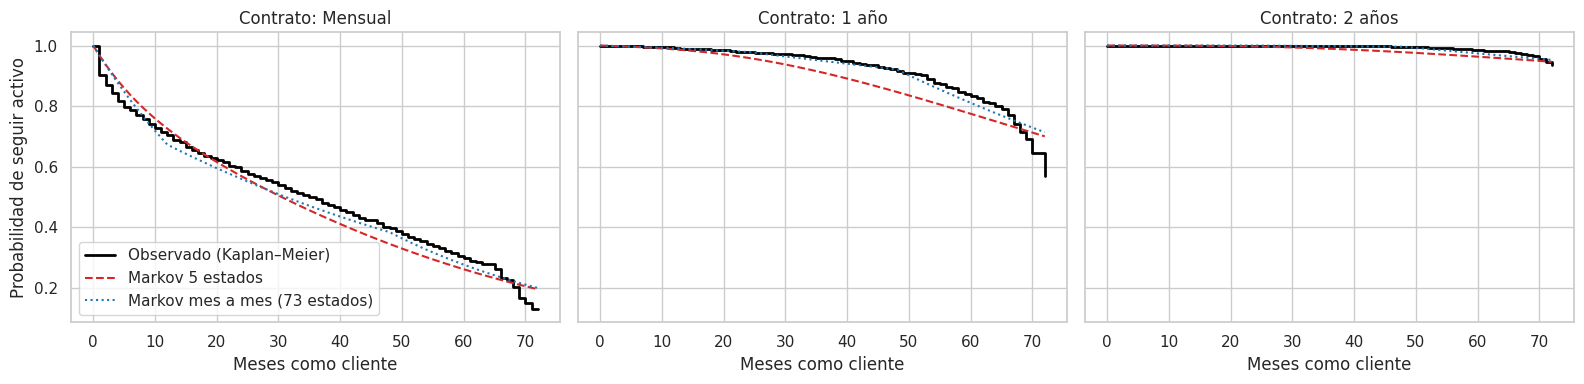

In [11]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, c in zip(ejes, CONTRATOS):
    ax.step(range(73), KM[c], where="post", label="Observado (Kaplan–Meier)", color="black", lw=2)
    ax.plot(S5[c], label="Markov 5 estados", color="tab:red", ls="--")
    ax.plot(S73[c], label="Markov mes a mes (73 estados)", color="tab:blue", ls=":")
    ax.set_title(f"Contrato: {c}")
    ax.set_xlabel("Meses como cliente")
ejes[0].set_ylabel("Probabilidad de seguir activo")
ejes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()

In [12]:
puntos = [12, 24, 36, 48, 60]
filas = []
for c in CONTRATOS:
    for t in puntos:
        filas.append({"contrato": c, "mes": t, "observado": KM[c][t], "5 estados": S5[c][t], "73 estados": S73[c][t]})
val = pd.DataFrame(filas)
val["error 5 est. (pp)"] = (val["5 estados"] - val["observado"]) * 100
val["error 73 est. (pp)"] = (val["73 estados"] - val["observado"]) * 100
display(val)

print("Error absoluto máximo (puntos porcentuales, meses 12–60):")
print("   5 estados :", round(val["error 5 est. (pp)"].abs().max(), 2))
print("   73 estados:", round(val["error 73 est. (pp)"].abs().max(), 2))

,contrato,mes,observado,5 estados,73 estados,error 5 est. (pp),error 73 est. (pp)
0,Mensual,12,0.7031,0.7254,0.6726,2.2316,-3.0521
1,Mensual,24,0.5859,0.5683,0.5592,-1.7631,-2.6682
2,Mensual,36,0.4911,0.4462,0.4629,-4.4887,-2.8226
3,Mensual,48,0.3973,0.3442,0.3831,-5.3061,-1.4140
4,Mensual,60,0.2972,0.2606,0.2759,-3.6534,-2.1304
5,1 año,12,0.9908,0.9874,0.9909,-0.3424,0.0136
6,1 año,24,0.9783,0.9590,0.9785,-1.9267,0.0235
7,1 año,36,0.9593,0.9106,0.9493,-4.8673,-0.9983
8,1 año,48,0.9165,0.8468,0.9210,-6.9767,0.4465
9,1 año,60,0.8318,0.7745,0.8105,-5.7352,-2.1290


Error absoluto máximo (puntos porcentuales, meses 12–60):
   5 estados : 6.98
   73 estados: 3.05


In [13]:
# Meses activos esperados en 5 años (horizonte H): comparación de los tres enfoques
def meses_activos_desde_S(S, H=H):
    return S[:H].sum()      # suma de S(0), S(1), ..., S(H-1)

comparacion = pd.DataFrame({
    "Observado (KM)": [meses_activos_desde_S(KM[c]) for c in CONTRATOS],
    "Markov 5 estados": [meses_activos_desde_S(S5[c]) for c in CONTRATOS],
    "Markov 73 estados": [meses_activos_desde_S(S73[c]) for c in CONTRATOS],
}, index=CONTRATOS)
print(f"Meses activos esperados de un cliente nuevo en los primeros {H} meses:")
comparacion

Meses activos esperados de un cliente nuevo en los primeros 60 meses:


,Observado (KM),Markov 5 estados,Markov 73 estados
Mensual,33.5021,32.6222,32.7336
1 año,57.3416,55.2705,57.0194
2 años,59.8618,59.3728,59.7809


## 9. Guardar resultados para el notebook 03

In [14]:
# Parámetros estimados (meses en riesgo y probabilidad mensual) por contrato y etapa
tabla_hazards.to_csv("hazards_mensuales.csv", index=False)

# Matrices de transición de 5 estados por contrato
filas = []
for c in CONTRATOS:
    mat = pd.DataFrame(P5[c], index=ESTADOS, columns=ESTADOS)
    mat.insert(0, "desde", ESTADOS)
    mat.insert(0, "contrato", c)
    filas.append(mat)
pd.concat(filas).to_csv("matrices_transicion_5estados.csv", index=False)

print("Guardados: hazards_mensuales.csv y matrices_transicion_5estados.csv")

# En Colab: descarga los archivos a tu computadora (luego se suben a data/processed/ del repo)
try:
    from google.colab import files
    files.download("hazards_mensuales.csv")
    files.download("matrices_transicion_5estados.csv")
except ImportError:
    pass

Guardados: hazards_mensuales.csv y matrices_transicion_5estados.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>